In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [2]:
source_file = (
    Path("/home/csb/Saloni/IDEAS_ID/IDEAS/Computation/source_data")
    / "Pattabiraman_ID_scores.csv"
)

data = pd.read_csv(source_file)

if not {"Sample", "ID"}.issubset(data.columns):
    raise ValueError("CSV must contain 'Sample' and 'ID' columns")

data["Sample"] = data["Sample"].astype(str)
data["ID"] = pd.to_numeric(data["ID"])

sample_order = sorted(data["Sample"].unique())

id_groups = [
    data.loc[data["Sample"] == sample, "ID"].dropna().to_numpy()
    for sample in sample_order
]

id_means = [np.mean(group) for group in id_groups]
cell_counts = data["Sample"].value_counts()

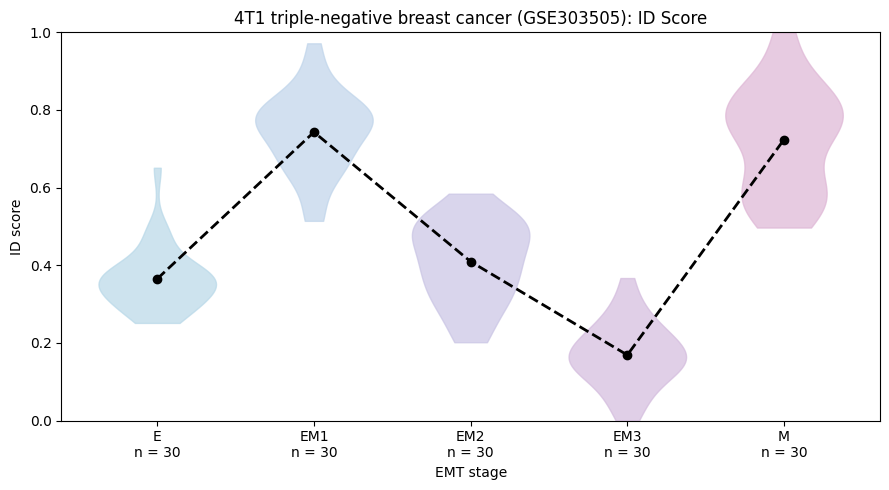

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(sample_order))

pastel_colors = [
    "#B8D8E8",
    "#BFD4EA",
    "#C9C4E4",
    "#D3BBDD",
    "#DEB6D5",
    "#E8B8C8",
    "#F0C1B8",
]

parts = ax.violinplot(
    id_groups,
    positions=positions,
    widths=0.75,
    showmeans=False,
    showmedians=False,
    showextrema=False,
)

for body, color in zip(parts["bodies"], pastel_colors):
    body.set_facecolor(color)
    body.set_edgecolor(color)
    body.set_alpha(0.7)

ax.plot(
    positions,
    id_means,
    linestyle="--",
    marker="o",
    linewidth=2,
    markersize=6,
    color="black",
)

ax.set_xticks(positions)
ax.set_xticklabels([
    f"{sample}\nn = {cell_counts.loc[sample]}"
    for sample in sample_order
])

ax.set_xlabel("EMT stage")
ax.set_ylabel("ID score")
ax.set_ylim(0, 1)
ax.set_title(
    "4T1 triple-negative breast cancer (GSE303505): ID Score"
)

plt.tight_layout()
plt.show()

In [4]:
tukey = pairwise_tukeyhsd(
    endog=data["ID"],
    groups=data["Sample"],
    alpha=0.05,
)

tukey_df = pd.DataFrame(
    tukey._results_table.data[1:],
    columns=tukey._results_table.data[0],
)

tukey_df["group1"] = tukey_df["group1"].astype(str)
tukey_df["group2"] = tukey_df["group2"].astype(str)
tukey_df["p-adj"] = pd.to_numeric(tukey_df["p-adj"])

tukey_matrix = pd.DataFrame(
    np.nan,
    index=sample_order,
    columns=sample_order,
)

for _, row in tukey_df.iterrows():
    tukey_matrix.loc[row["group1"], row["group2"]] = row["p-adj"]
    tukey_matrix.loc[row["group2"], row["group1"]] = row["p-adj"]

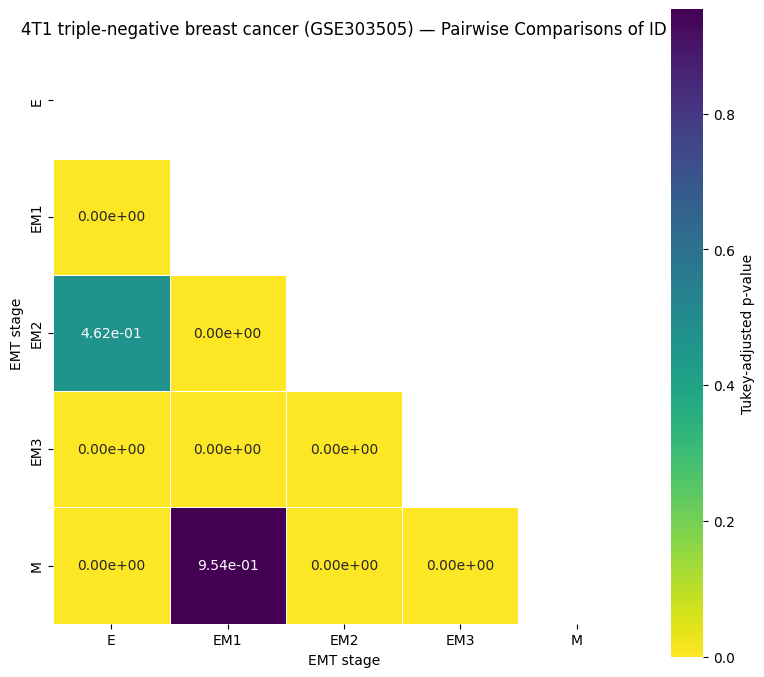

In [5]:
mask = np.triu(
    np.ones_like(tukey_matrix, dtype=bool)
)

plt.figure(figsize=(8, 7))

sns.heatmap(
    tukey_matrix,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Tukey-adjusted p-value"},
)

plt.title(
    "4T1 triple-negative breast cancer (GSE303505)"
    " — Pairwise Comparisons of ID"
)
plt.xlabel("EMT stage")
plt.ylabel("EMT stage")
plt.tight_layout()
plt.show()